# 05. MC-LSTM — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: MC-LSTM (`model: mclstm`) — 순환(질량보존)
**한 줄 요약**: 질량보존 LSTM. 강우(mm/h)를 질량으로 받아 셀에 저장·재분배·방출하므로 입력 강우량을 초과하는 유출을 낼 수 없음.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **MC-LSTM 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/mclstm_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**MC-LSTM (Mass-Conserving LSTM; Hoedt et al., 2021; NeuralHydrology `mclstm`)**

LSTM의 셀 상태를 **보존량(질량)** 으로 재해석한 모델이다. 하나의 **질량 입력** $x_t^{m}$(강우, mm/h)과 보조 입력 $x_t^{a}$(표준화된 다른
강우 변수)를 받아 다음을 계산한다.

$$
\begin{aligned}
\mathbf{i}_t &= \mathrm{softmax}(\cdot) \;\; \text{(입력 게이트: 질량을 셀들에 분배, 합 = 1)} \\
\mathbf{R}_t &= \text{행 정규화된 재분배 행렬 (셀 간 질량 이동)} \\
\mathbf{o}_t &= \sigma(\cdot) \;\; \text{(출력 게이트: 각 셀에서 내보낼 비율)} \\
\mathbf{c}_t &= (1 - \mathbf{o}_t) \odot \left(\mathbf{R}_t^\top \mathbf{c}_{t-1} + \mathbf{i}_t x_t^{m}\right), \qquad
\hat y_t = \sum_{k \ne \text{trash}} \big[\mathbf{o}_t \odot (\mathbf{R}_t^\top \mathbf{c}_{t-1} + \mathbf{i}_t x_t^{m})\big]_k
\end{aligned}
$$

모든 연산이 질량을 보존하므로 **(입력 누적) = (저류) + (출력 누적) + (trash cell)** 이 항상 성립한다. trash cell은 증발산처럼 유출로
나타나지 않는 손실을 흡수하는 특수 셀이다. 출력은 head 없이 질량 유출의 합으로 정의된다.

### 1.1 수문학적 관점에서의 특징

- **물수지를 구조적으로 보장**한다. 학습 자료에 없는 극한 강우에서도 강우량보다 큰 유출을 만들 수 없어 외삽이 물리적으로 안전하다.
- 질량 입력과 목표가 같은 단위여야 하므로 유입량을 **mm/h**로 변환(`inflow_mm = Q × 3.6 / 930.42 km²`)해 학습하고, 평가 시 다시 m³/s로
  되돌린다. 입력·목표 모두 **표준화하지 않는다**(`custom_normalization: none`).
- 강우가 하나의 스칼라여야 하므로 입력세트 B에서는 7개 관측소의 **산술평균**(`rf_stn_mean`)을 질량 입력으로, 관측소별 값은 보조(게이트)
  입력으로 쓴다. 세트 A/C에서는 유역평균 강우가 질량 입력이다.
- 손실이 표준화되지 않은 mm/h 단위로 계산되므로 다른 모델과 **학습 손실 값의 크기를 직접 비교할 수 없다**(학습곡선 해석 시 주의).

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `mass_inputs` | rf_avg (A, C) / rf_stn_mean (B) | 질량 입력은 하나여야 함 |
| `dynamic_inputs` | 나머지 강우 변수(보조 입력) | 게이트 계산에만 사용 |
| `target_variables` | inflow_mm | 질량 입력과 같은 단위(mm/h) |
| `custom_normalization` | 질량 입력·목표: none | 질량보존을 위해 표준화 금지 |
| `hidden_size` | 64 | 셀 64개(그중 1개는 trash cell) |
| `initial_forget_bias` | 3 | 학습 초기 출력 게이트를 열어 둠 |

### 참고문헌

- Hoedt, P.-J., Kratzert, F., Klotz, D., Halmich, C., Holzleitner, M., Nearing, G., Hochreiter, S., & Klambauer, G. (2021). MC-LSTM: Mass-conserving LSTM. *ICML*.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "mclstm"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

MC-LSTM -> mclstm


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

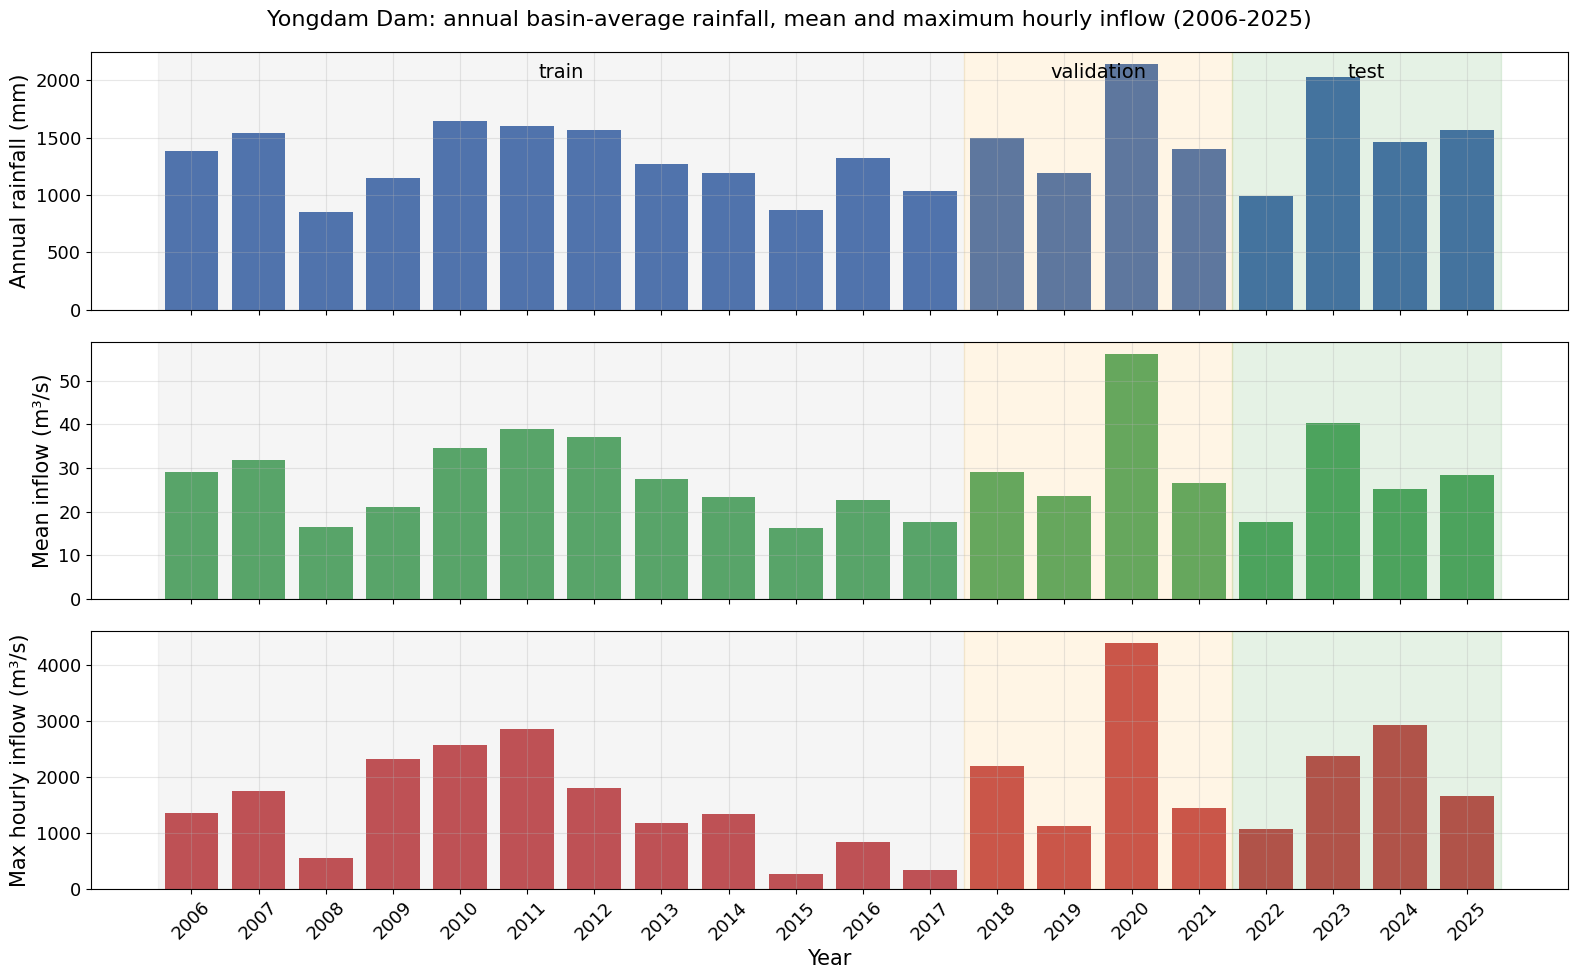

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/mclstm_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,mclstm_A,mclstm_B,mclstm_C
target_variables,['inflow_mm'],['inflow_mm'],['inflow_mm']
clip_targets_to_zero,['inflow_mm'],['inflow_mm'],['inflow_mm']
model,mclstm,mclstm,mclstm
hidden_size,64,64,64
initial_forget_bias,3,3,3
mass_inputs,['rf_avg'],['rf_stn_mean'],['rf_avg']
dynamic_inputs,['rf_avg_aux'],"['rf_9000028', 'rf_9000027', 'rf_9000023', 'rf...","['rf_9000028', 'rf_9000027', 'rf_9000023', 'rf..."
custom_normalization,"{'rf_avg': {'centering': 'none', 'scaling': 'n...","{'rf_stn_mean': {'centering': 'none', 'scaling...","{'rf_avg': {'centering': 'none', 'scaling': 'n..."


experiment_name: mclstm_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length: 720
predict_last_n: 1
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- inflow_mm
clip_targets_to_zero:
- 

## 3. 학습

`common.train()` 은 완료된 run (`runs/mclstm_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/mclstm_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[mclstm_A] completed run found, skipping training: mclstm_A_2010_133216
Set A: run=mclstm_A_2010_133216  epochs=50  best=49  params=283,008  753 s/epoch
[mclstm_B] completed run found, skipping training: mclstm_B_2010_133358
Set B: run=mclstm_B_2010_133358  epochs=44  best=39  params=308,352  768 s/epoch
[mclstm_C] completed run found, skipping training: mclstm_C_2010_133841


Set C: run=mclstm_C_2010_133841  epochs=50  best=49  params=312,576  759 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

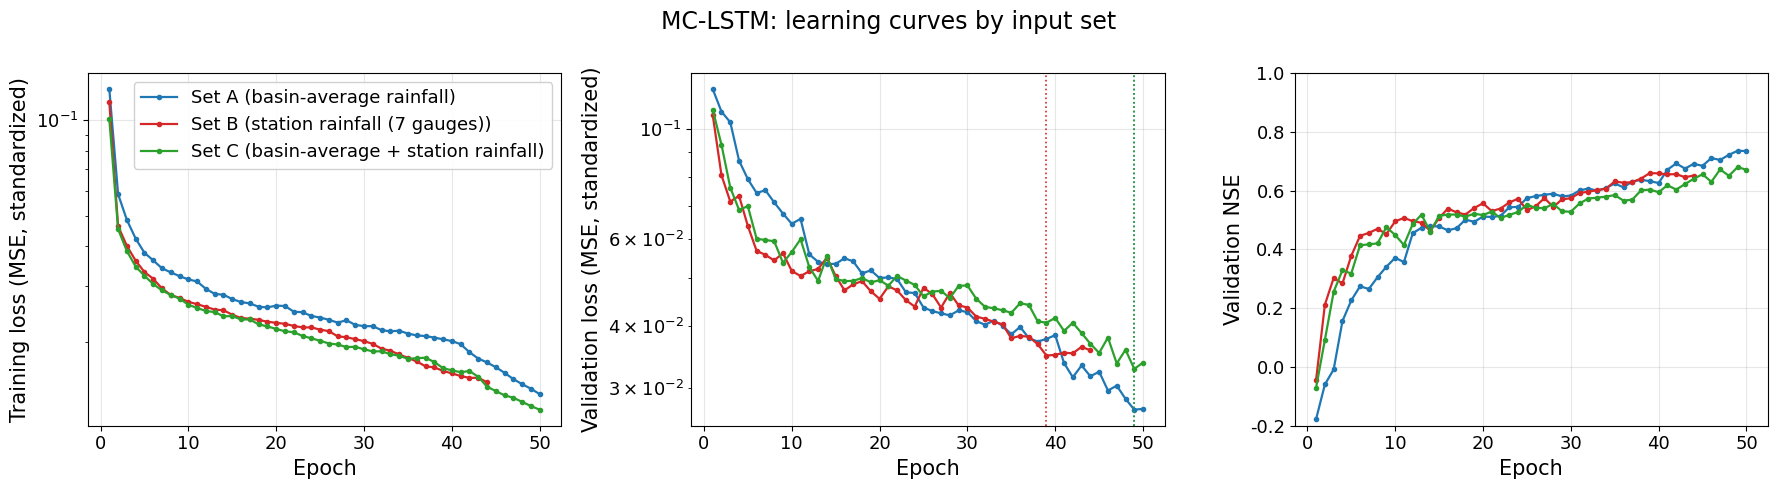

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE     FHV       FMS      FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                           
A   train       0.636  0.624  43.404  19.810 -27.900      0.805      0.841    -0.103 -11.406   515.579 -246.279        6.018     61.826         0.658
    validation  0.735  0.615  60.197  23.490 -28.447      0.866      0.777    -0.082 -17.638   575.088  -24.639        3.732     52.072         0.683
    test        0.692  0.741  48.125  18.579 -17.652      0.836      0.905    -0.057  -6.375   248.270 -297.950        2.865     35.583         0.666
B   train       0.583  0.360  46.834  22.858 -57.326      0.792      0.805    -0.211 -18.715  2373.412 -772.078        6.070     73.878         0.596
    validation  0.660  0.347  68.283  27.244 -56.705      0.837      0.720    -0.164 -25.547  2582.868 -523.460        4.000     73.591         0.606
    test        0.576  0.420  56.427  22.594 -50.726      0.778      0.828    -0.163 -14.126  1228.194 -990.837        2.288     43.254         0.568
C   train       0.672  0.567  41.503  20.585 -36.296      0.831      0.834    -0.133 -13.759   826.143 -499.547        6.067     63.903         0.650
    validation  0.680  0.494  66.190  24.610 -37.582      0.845      0.698    -0.109 -22.280   914.723 -141.594        4.073     54.148         0.676
    test        0.672  0.639  49.641  19.724 -28.162      0.825      0.856    -0.091  -9.088   413.420 -611.378        2.500     44.435         0.641

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

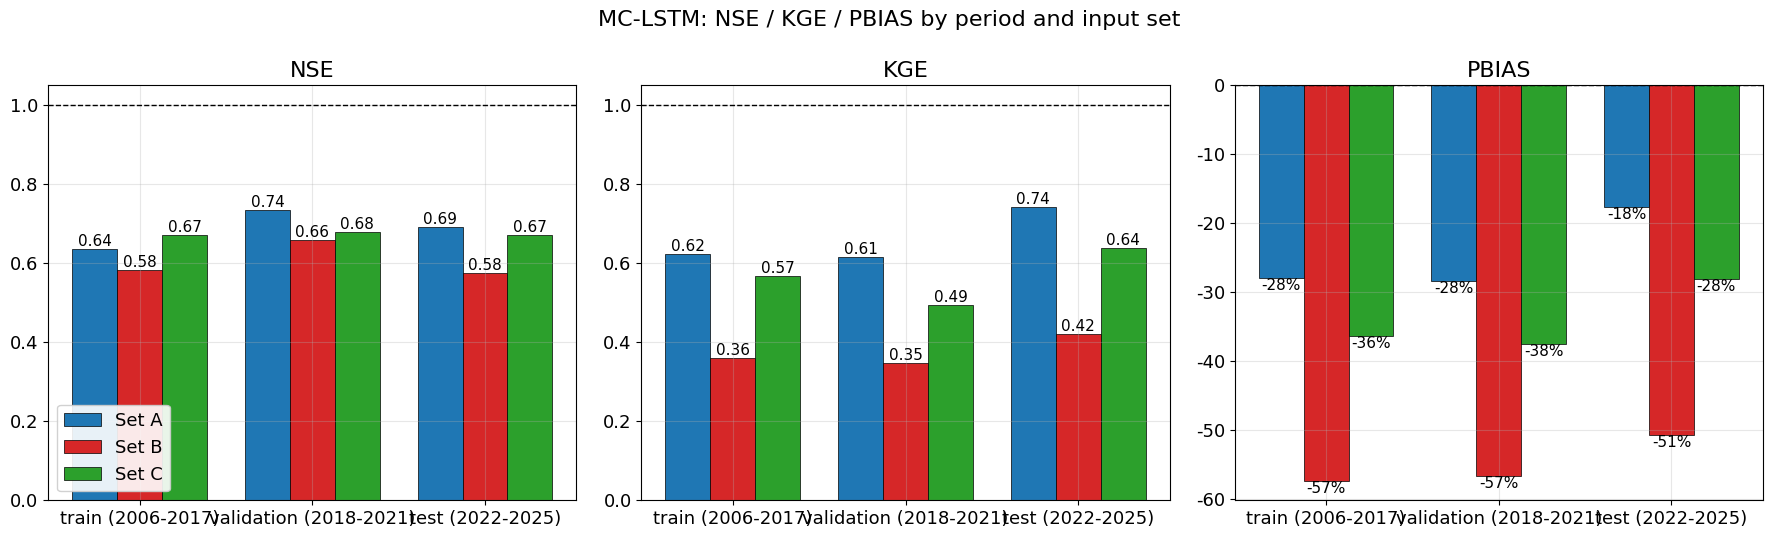

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

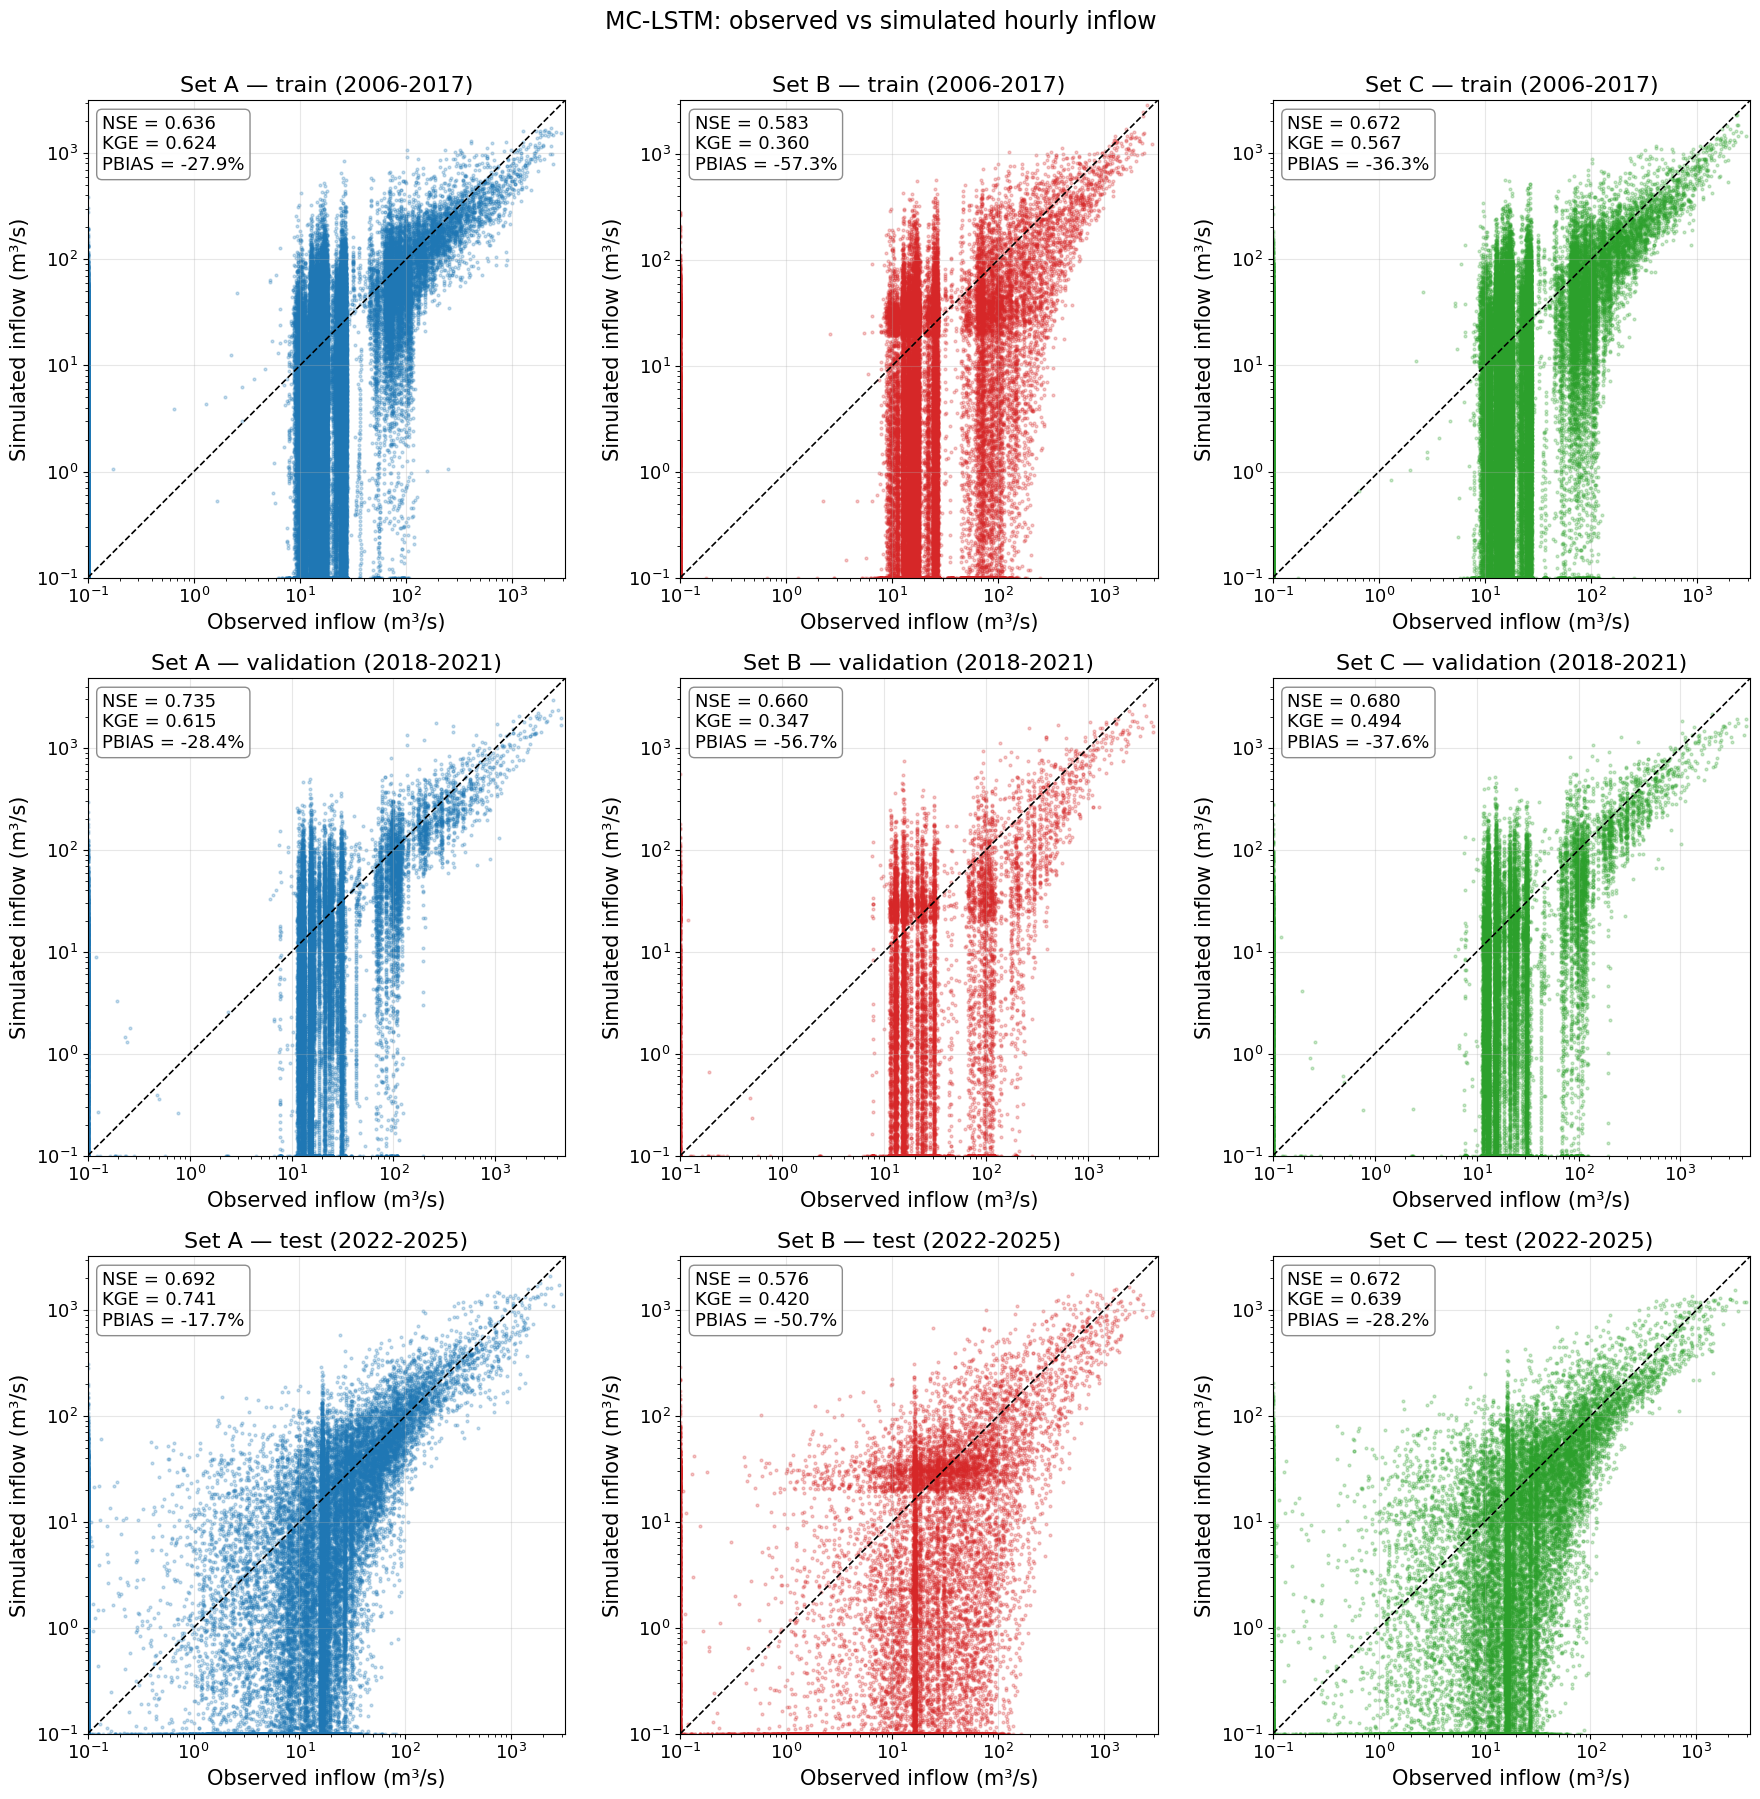

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

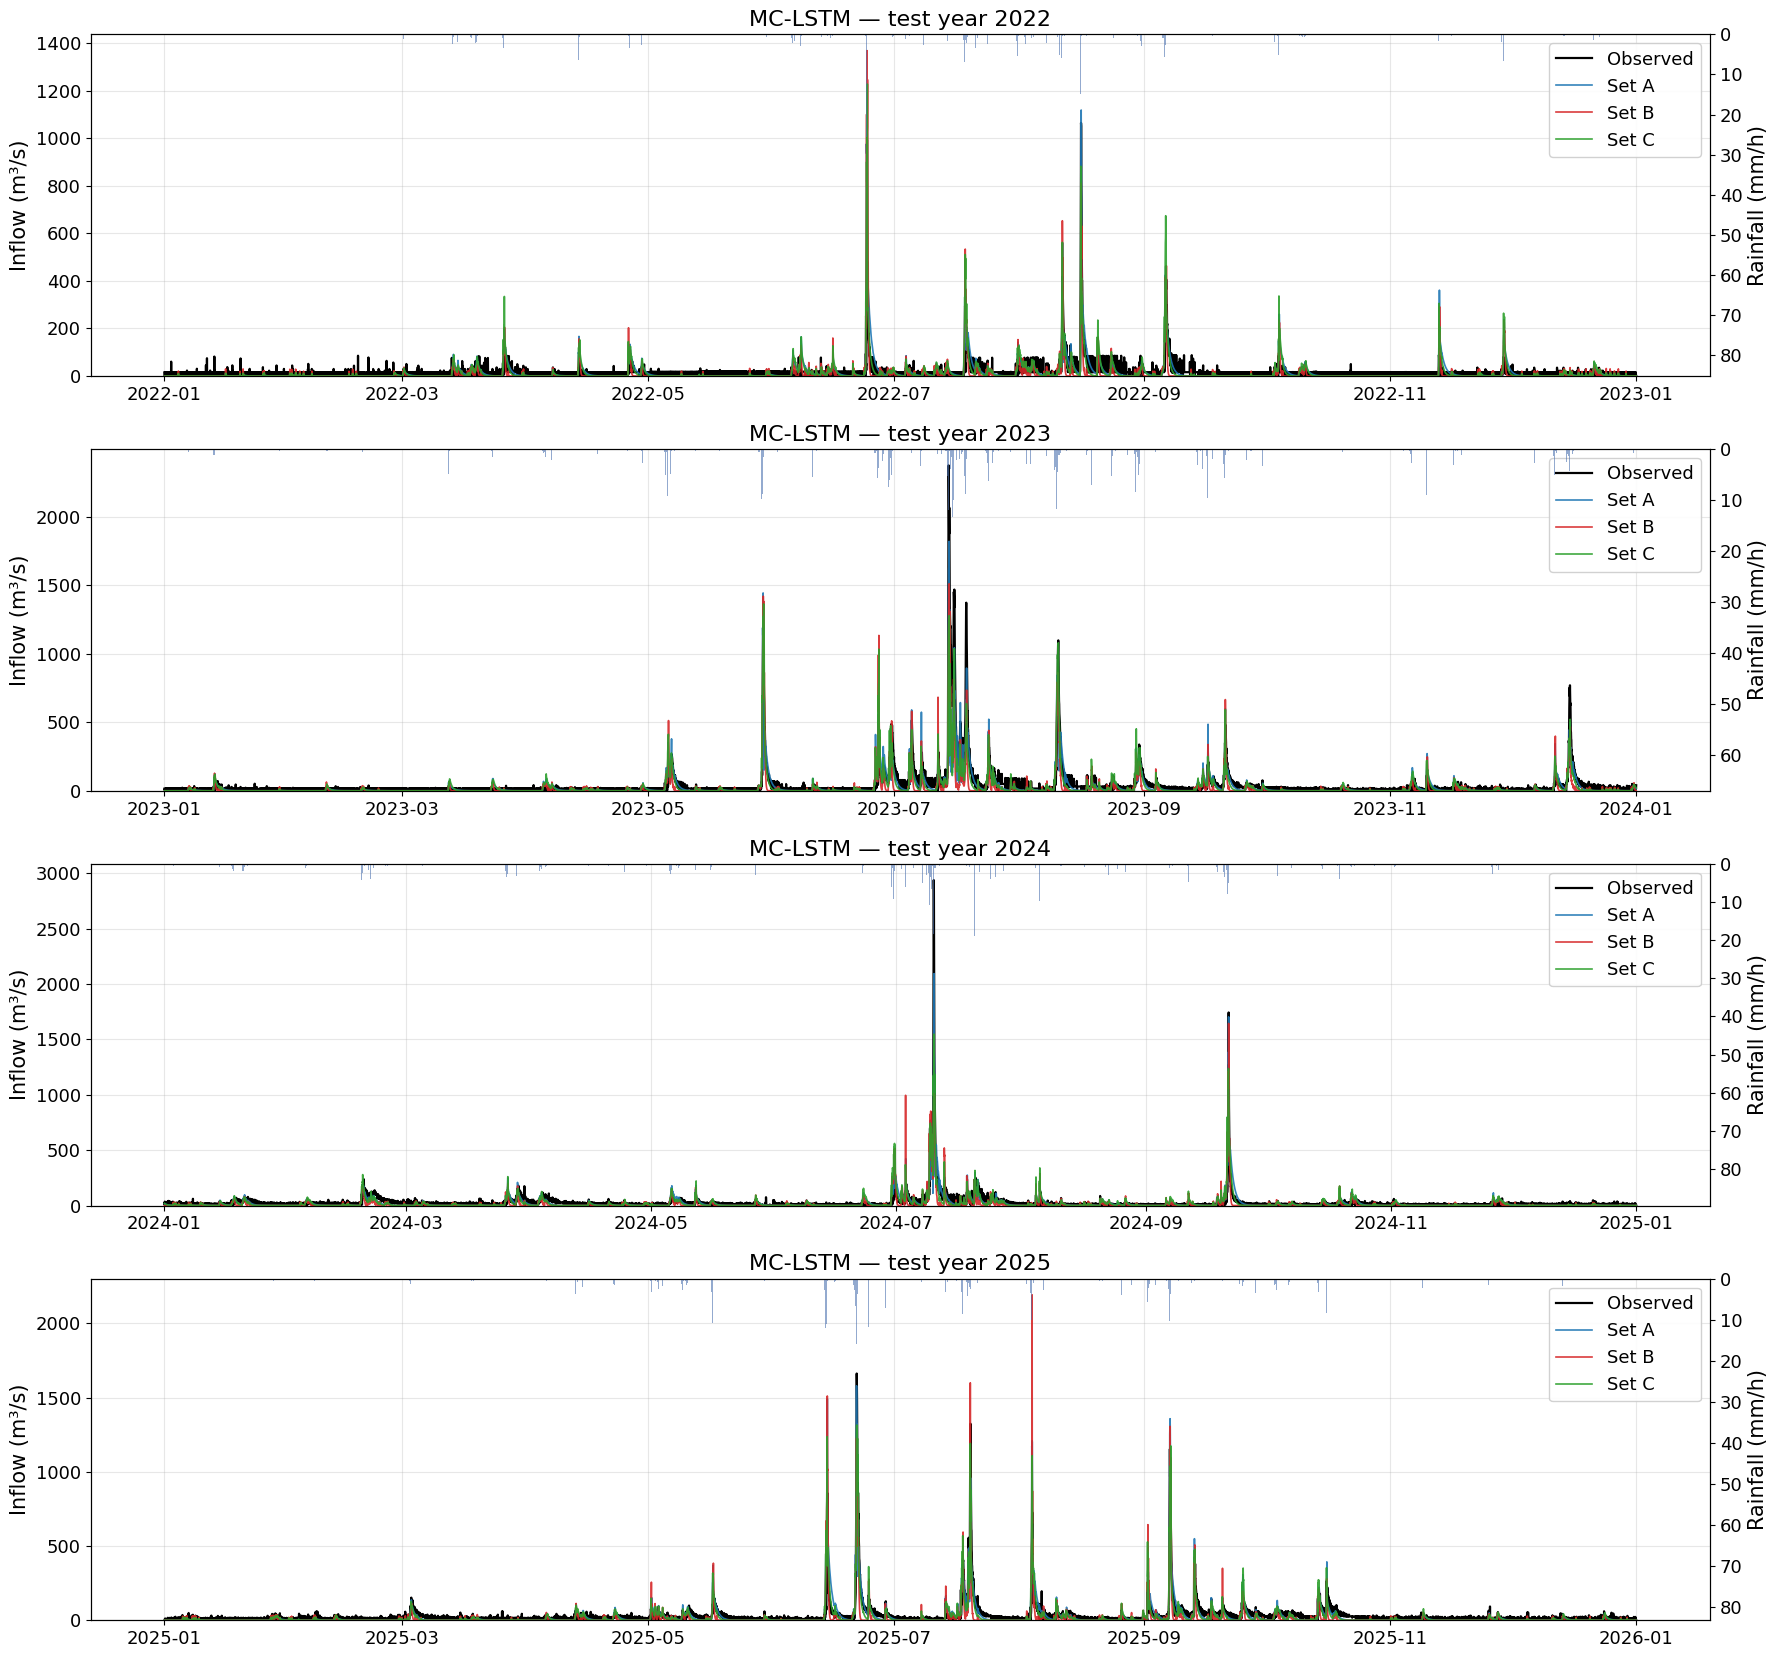

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

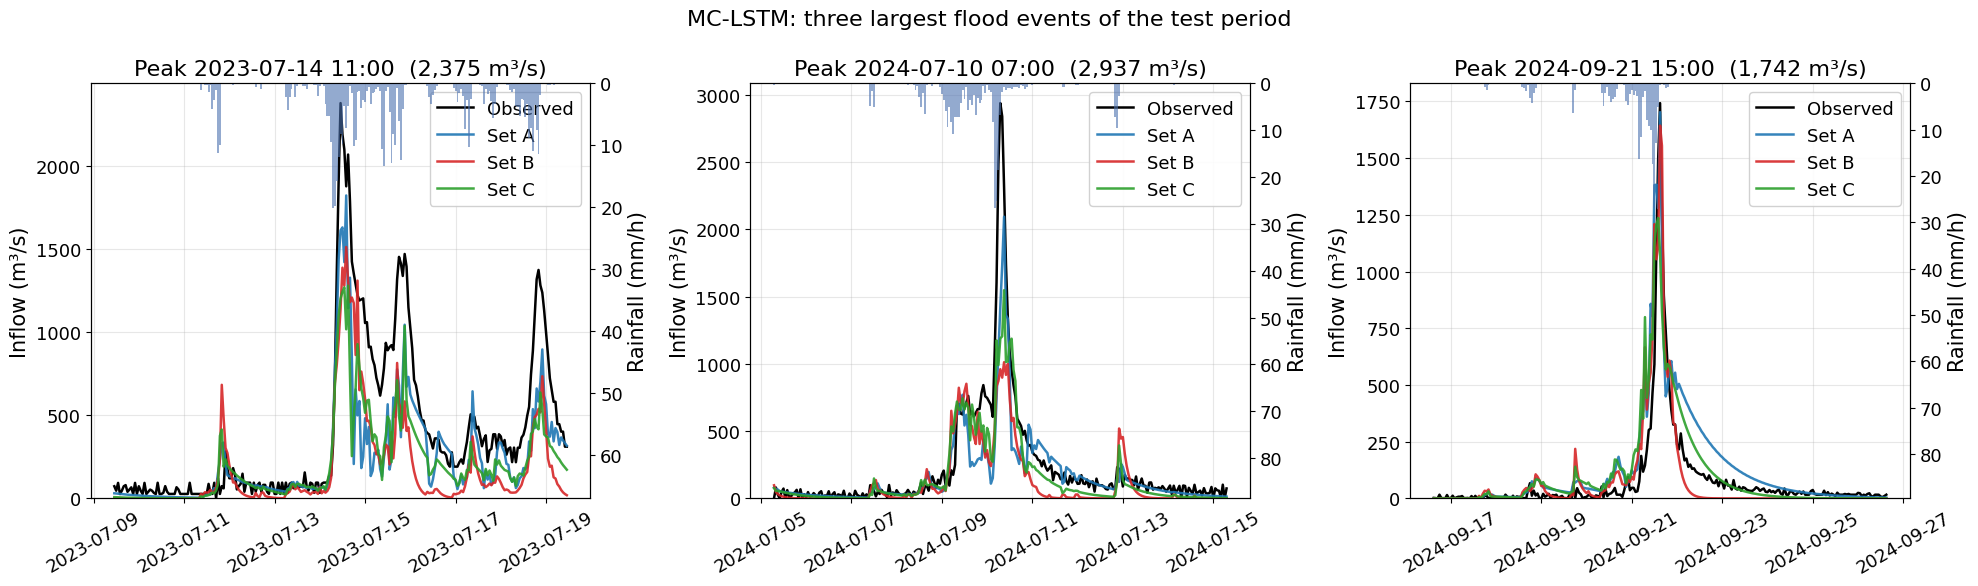

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

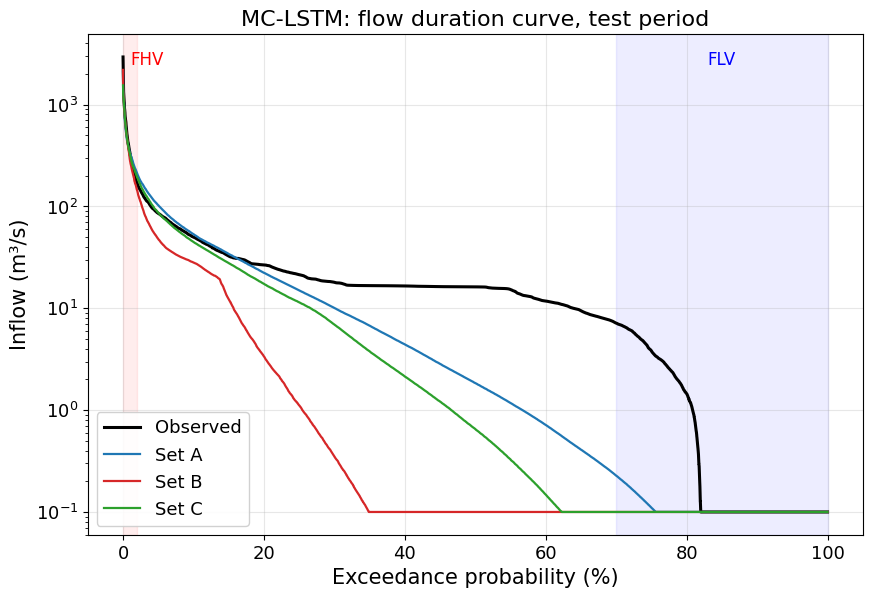

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

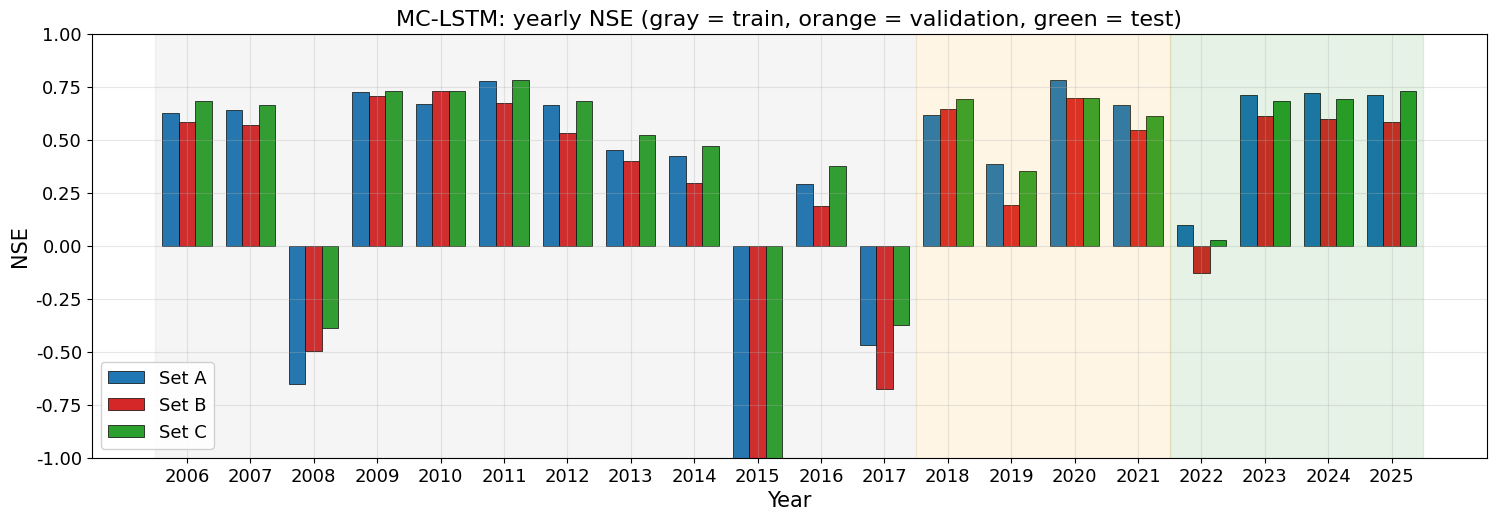

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006  0.628  0.515  0.584  0.291  0.683  0.517
2007  0.643  0.624  0.570  0.362  0.666  0.580
2008 -0.653  0.138 -0.498  0.133 -0.388  0.214
2009  0.725  0.686  0.709  0.430  0.733  0.594
2010  0.670  0.567  0.730  0.444  0.734  0.565
2011  0.777  0.565  0.675  0.301  0.785  0.511
2012  0.664  0.553  0.535  0.293  0.686  0.496
2013  0.453  0.599  0.400  0.345  0.526  0.537
2014  0.424  0.629  0.296  0.319  0.474  0.538
2015 -1.266  0.119 -1.120  0.082 -1.383  0.087
2016  0.293  0.611  0.189  0.388  0.380  0.603
2017 -0.466  0.293 -0.676  0.165 -0.374  0.341
2018  0.619  0.732  0.646  0.473  0.694  0.680
2019  0.388  0.611  0.193  0.297  0.356  0.546
2020  0.785  0.512  0.698  0.289  0.699  0.377
2021  0.667  0.675  0.547  0.361  0.612  0.558
2022  0.100  0.466 -0.127  0.270  0.028  0.456
2023  0.712  0.645  0.613  0.372  0.684  0.557
2024  0.723  0.732  0.599  0.401  0.695  0.663
2025  0.711  0.791  0.584  0.472  0.731  0.696

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: A


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,1118.8,2022-08-16 08:00:00,5.1,1.0,-0.9,0.9
2023-05-29 14:00:00,915.1,1443.8,2023-05-29 11:00:00,57.8,-3.0,38.6,0.3
2023-06-27 02:00:00,506.0,671.9,2023-06-27 05:00:00,32.8,3.0,13.1,0.2
2023-07-05 08:00:00,515.2,590.1,2023-07-05 07:00:00,14.5,-1.0,-17.1,0.4
2023-07-14 11:00:00,2375.1,1820.2,2023-07-14 14:00:00,-23.4,3.0,-40.7,0.6
2023-07-18 20:00:00,1372.7,895.1,2023-07-18 22:00:00,-34.8,2.0,-32.8,0.6
2023-08-10 16:00:00,1097.7,843.1,2023-08-10 09:00:00,-23.2,-7.0,-7.8,0.7
2023-12-15 13:00:00,769.9,497.0,2023-12-15 14:00:00,-35.4,1.0,-29.4,0.7
2024-07-10 07:00:00,2936.8,2092.7,2024-07-10 09:00:00,-28.7,2.0,-24.9,0.7


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,5.87,15.94,-1.30
peak_error_median_pct,-2.30,-5.69,-13.43
peak_abs_error_mean_pct,29.93,51.28,34.91
timing_error_mean_h,0.00,0.07,0.47
timing_abs_error_mean_h,2.00,1.53,1.53
timing_within_3h_frac,0.93,1.00,0.87
peak_within_20pct_frac,0.33,0.20,0.33
volume_error_mean_pct,8.55,-32.03,-11.39
event_NSE_median,0.66,0.46,0.65


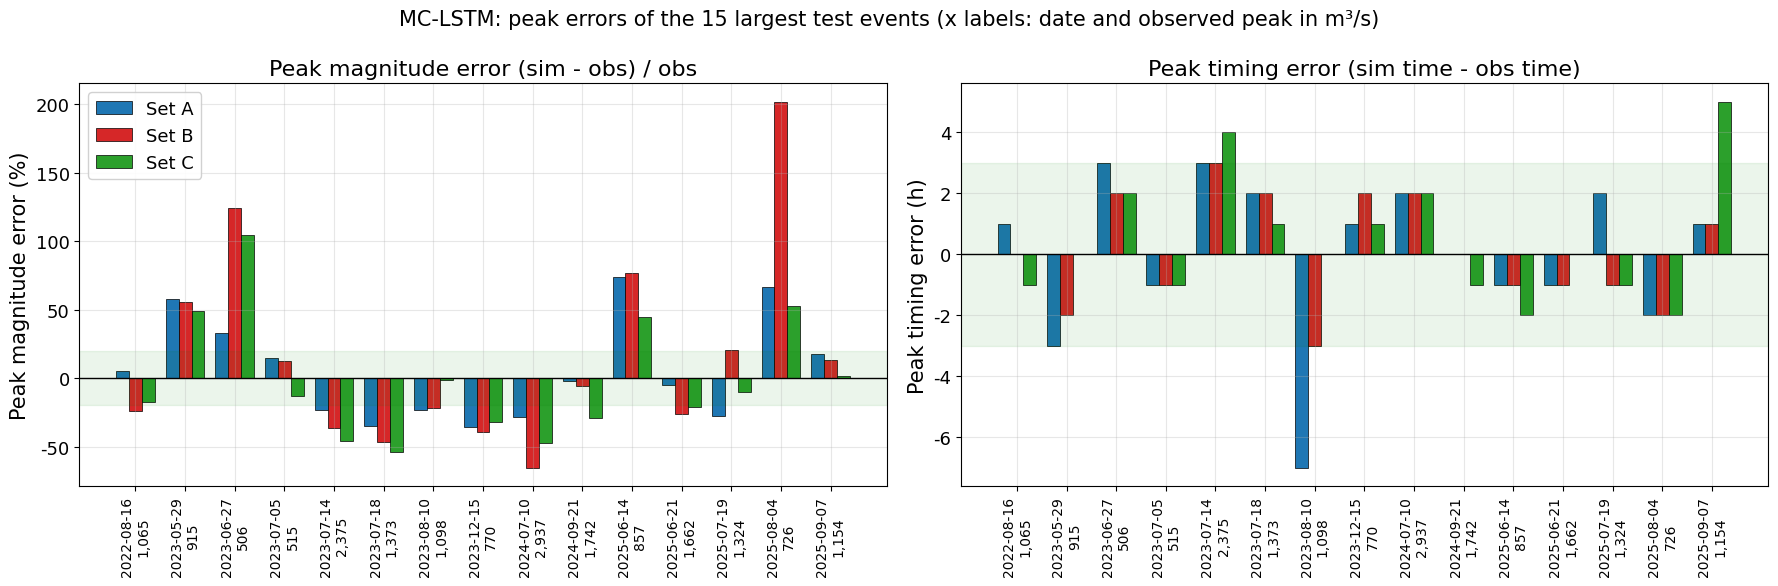

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**MC-LSTM / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.692, KGE 0.741, RMSE 48.1 m³/s, PBIAS -17.7%.
- 학습(0.636)·검증(0.735)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과소 추정하는 경향(PBIAS -17.7%)이 뚜렷합니다.
- 고유량 구간(FHV -6.4%)은 과소 재현되고, 저유량 구간(FLV -297.9%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -2.3%, 평균 절대 첨두오차 29.9%, 첨두 시각 오차 평균 +0.0 h (±3 h 이내 93%, 크기 ±20% 이내 33%).
- 학습: 50 epoch (최대 50 epoch 도달), 최적 epoch 49, epoch당 평균 753 s, 총 학습시간 630.1 min, 파라미터 283,008개.

**MC-LSTM / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.576, KGE 0.420, RMSE 56.4 m³/s, PBIAS -50.7%.
- 학습(0.583)·검증(0.660)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과소 추정하는 경향(PBIAS -50.7%)이 뚜렷합니다.
- 고유량 구간(FHV -14.1%)은 과소 재현되고, 저유량 구간(FLV -990.8%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -5.7%, 평균 절대 첨두오차 51.3%, 첨두 시각 오차 평균 +0.1 h (±3 h 이내 100%, 크기 ±20% 이내 20%).
- 학습: 44 epoch (early stopping), 최적 epoch 39, epoch당 평균 768 s, 총 학습시간 566.1 min, 파라미터 308,352개.

**MC-LSTM / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.672, KGE 0.639, RMSE 49.6 m³/s, PBIAS -28.2%.
- 학습(0.672)·검증(0.680)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과소 추정하는 경향(PBIAS -28.2%)이 뚜렷합니다.
- 고유량 구간(FHV -9.1%)은 과소 재현되고, 저유량 구간(FLV -611.4%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -13.4%, 평균 절대 첨두오차 34.9%, 첨두 시각 오차 평균 +0.5 h (±3 h 이내 87%, 크기 ±20% 이내 33%).
- 학습: 50 epoch (최대 50 epoch 도달), 최적 epoch 49, epoch당 평균 759 s, 총 학습시간 632.8 min, 파라미터 312,576개.

### 7.2 MC-LSTM 의 결과 해석

**요약**: 테스트 NSE 0.69 (A), 0.58 (B), 0.67 (C). 질량보존 구조가 주는 물리적 일관성과 맞바꾼 정확도 손실이 뚜렷하며, 가장 큰 특징은
**총량 과소 추정**(PBIAS −18 ~ −51%)이다.

- **총량·저유량**: 질량보존 모델은 들어온 강우보다 많은 유출을 낼 수 없고, trash cell 이 흡수한 물은 영원히 사라진다. 결과적으로 건기
  기저유출을 거의 0 에 가깝게 내려(다른 모델과 달리 FLV 가 크게 음수) 총량이 부족해진다. 입력 강우만으로는 지하수 기여를 설명할 수 없다는
  점에서 이는 모델의 한계이자 자료의 한계이기도 하다.
- **홍수 첨두**: 첨두 크기 오차 **중앙값은 −2 ~ −13% 로 작지만** 평균 절대 오차는 30–51% 로 사건별 산포가 크다. 즉 어떤 사건은 잘 맞추고
  어떤 사건은 크게 놓친다. 첨두 시각 오차 1.5–2.0 h, ±3 h 이내 87–100% 로 시각은 좋다.
- **입력세트 효과**: 관측소별 강우(B)는 질량 입력이 7개 관측소 평균이 되고 보조 입력 7개가 게이트를 제어하는데, 이 조합이 가장 나빴다
  (NSE 0.58, PBIAS −51%). 유역평균 강우를 질량 입력으로 쓰는 A, C 가 낫다.
- **일반화**: 검증 NSE(0.66–0.74)가 학습 NSE(0.58–0.67)보다 높다. 과적합은 없지만 50 epoch 에서도 수렴하지 않았다(최적 epoch 49–50).
- **비용**: 750–770 s/epoch 로 **LSTM 의 90배**, run 당 10–11 시간이 걸렸다. 720 단계를 파이썬 루프로 돌며 64×64 재분배 행렬을 계산하기
  때문이며, 파라미터도 28–31만 개로 순환 모델 중 가장 많다.


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/mclstm_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,283008,308352,312576
epochs trained,50,44,50
best epoch,49,39,49
early stopped,False,True,False
s / epoch,752.7,768.3,758.8
training time (min),630.1,566.1,632.8
test NSE,0.692,0.576,0.672
test KGE,0.741,0.42,0.639
test RMSE (m³/s),48.1,56.4,49.6
test PBIAS (%),-17.7,-50.7,-28.2
